# Lab 1 — Role A: Task 1 (Data Preparation) & Task 2 (AlexNet vs ResNet-18 Baselines)

本 Notebook 对应 Lab 1 的 **Task 1** 与 **Task 2**（Role A），采用「代码在 `lab1/src/`、展示在 `.ipynb`」模式，同时兼容 **本地 `.venv`（RTX 5070 Ti）** 与 **Google Colab（T4 GPU）**。

- **Task 1**：CIFAR-10 样本形态、分层类别分布（45k train / 5k val / 10k test，`SPLIT_SEED=2223`）、train-only RGB 归一化与随机性控制。
- **Task 2**：从零手写 Part A9 适配版 **AlexNet**（6.97M 参数）与 **ResNet-18**（11.17M 参数），追踪各阶段特征图尺寸，在统一 30-epoch 预算下对比训练/验证曲线、测试集精度、训练成本、峰值显存与推理吞吐，并保存最优权重登记至 `checkpoints_manifest.json`。

## Execution provenance

This notebook displays the original Task 1 and Task 2 experiment artifacts.
The two baseline models were trained and benchmarked on an NVIDIA GeForce RTX 5070 Ti Laptop GPU
using FP32, 30 epochs, 45,000 training images and 5,000 validation images.
Running the display cells in Colab does not change the provenance of those measurements.
The current display environment is printed separately below.

`RUN_TRAINING = False` loads the saved artifacts. Set it to `True` only to perform a fresh,
full baseline training run. Dataset preparation, model definitions, training and metrics
are implemented in the accompanying `lab1/src/` modules.


In [1]:
# 1. 环境初始化（自动识别本地 vs Colab）
from pathlib import Path
import os
import subprocess
import sys

IN_COLAB = "google.colab" in sys.modules or Path("/content").exists()
REPO_URL = "https://github.com/Mrpooool/ScalableMlLab.git"
BRANCH = "main"

if IN_COLAB:
    REPO_DIR = Path("/content/ScalableMlLab")
    if not REPO_DIR.exists():
        subprocess.run(["git", "clone", "-b", BRANCH, REPO_URL, str(REPO_DIR)], check=True)
    else:
        subprocess.run(["git", "-C", str(REPO_DIR), "pull"], check=True)
else:
    cwd = Path.cwd().resolve()
    REPO_DIR = next((p for p in [cwd, *cwd.parents] if (p / "lab1" / "src").exists()), cwd)

SRC_DIR = REPO_DIR / "lab1" / "src"
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))
os.chdir(REPO_DIR)

import pandas as pd
import torch
from IPython.display import Image, display

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Mode:", "Colab" if IN_COLAB else "Local", "| Device:", device,
      "| GPU:", torch.cuda.get_device_name(0) if device.type == "cuda" else "CPU")

Mode: Colab | Device: cpu | GPU: CPU


In [2]:
# Task 1 and Task 2: reuse verified experiment artifacts, or explicitly retrain.
RUN_TRAINING = False

from io_utils import load_json
from run_phase2_baselines import main as run_phase2_main

results_dir = REPO_DIR / "lab1" / "results"
if RUN_TRAINING:
    run_phase2_main()
else:
    required = ["task1_data_summary.json", "task2_architecture_profiles.json",
                "t2_alexnet_cifar_baseline_s42.json", "t2_resnet18_cifar_baseline_s42.json",
                "summary.csv", "figures/t1_class_distribution.png", "figures/t1_sample_grid.png",
                "figures/t2_learning_curves.png", "figures/t2_baseline_comparison.png"]
    missing = [name for name in required if not (results_dir / name).is_file()]
    if missing:
        raise FileNotFoundError(f"Missing saved artifacts: {missing}. Restore them before display.")
    print("Loaded original Phase 2 artifacts. No training or benchmark was rerun.")
    for name in ["t2_alexnet_cifar_baseline_s42", "t2_resnet18_cifar_baseline_s42"]:
        record = load_json(results_dir / f"{name}.json")
        print(name, "| original training device:", record["environment"]["device_name"],
              "| original benchmark device:", record["inference_benchmark"]["device_name"])


Loaded original Phase 2 artifacts. No training or benchmark was rerun.
t2_alexnet_cifar_baseline_s42 | original training device: NVIDIA GeForce RTX 5070 Ti Laptop GPU | original benchmark device: NVIDIA GeForce RTX 5070 Ti Laptop GPU
t2_resnet18_cifar_baseline_s42 | original training device: NVIDIA GeForce RTX 5070 Ti Laptop GPU | original benchmark device: NVIDIA GeForce RTX 5070 Ti Laptop GPU


Image shape (H,W,C): [32, 32, 3] | dtype: uint8 | pixel range: (0, 255)
Split counts: {'official_train_total': 50000, 'train_split': 45000, 'val_split': 5000, 'official_test': 10000}


,mean,std
red,0.491318,0.247001
green,0.482180,0.243401
blue,0.446389,0.261544


,train,val,test
airplane,4500,500,1000
automobile,4500,500,1000
bird,4500,500,1000
cat,4500,500,1000
deer,4500,500,1000
dog,4500,500,1000
frog,4500,500,1000
horse,4500,500,1000
ship,4500,500,1000
truck,4500,500,1000


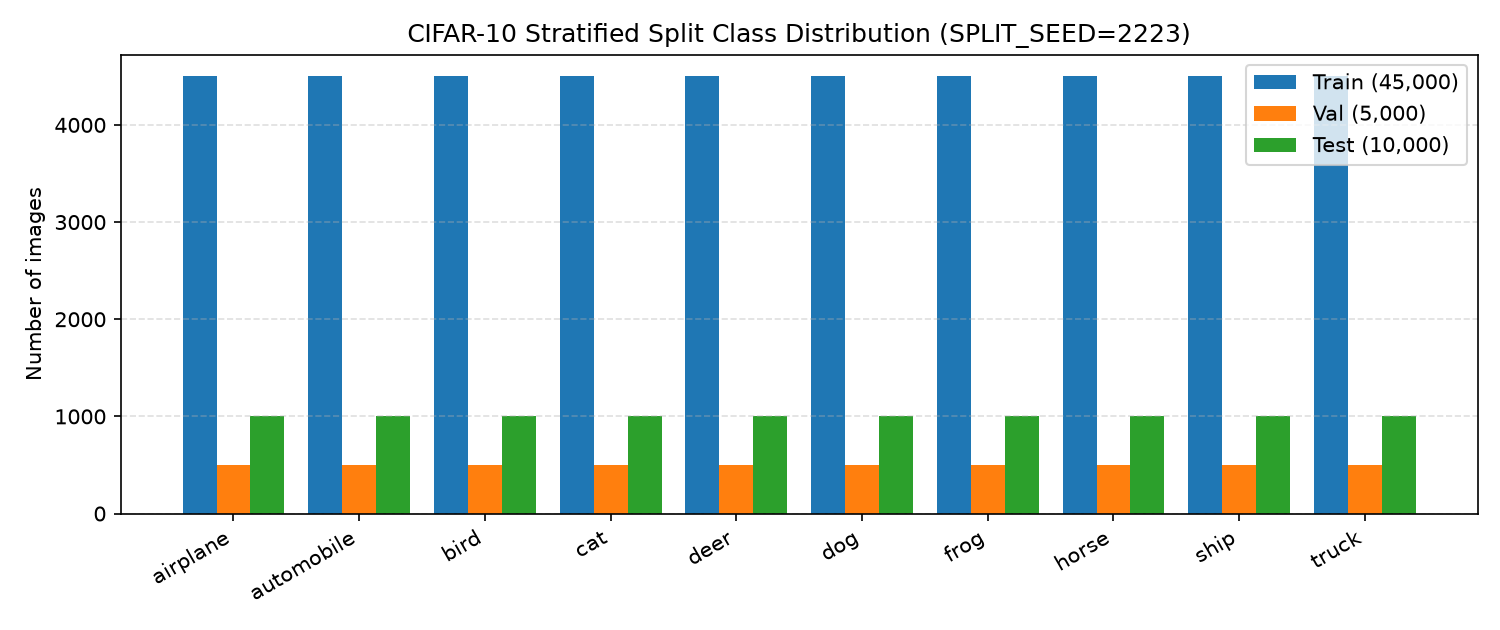

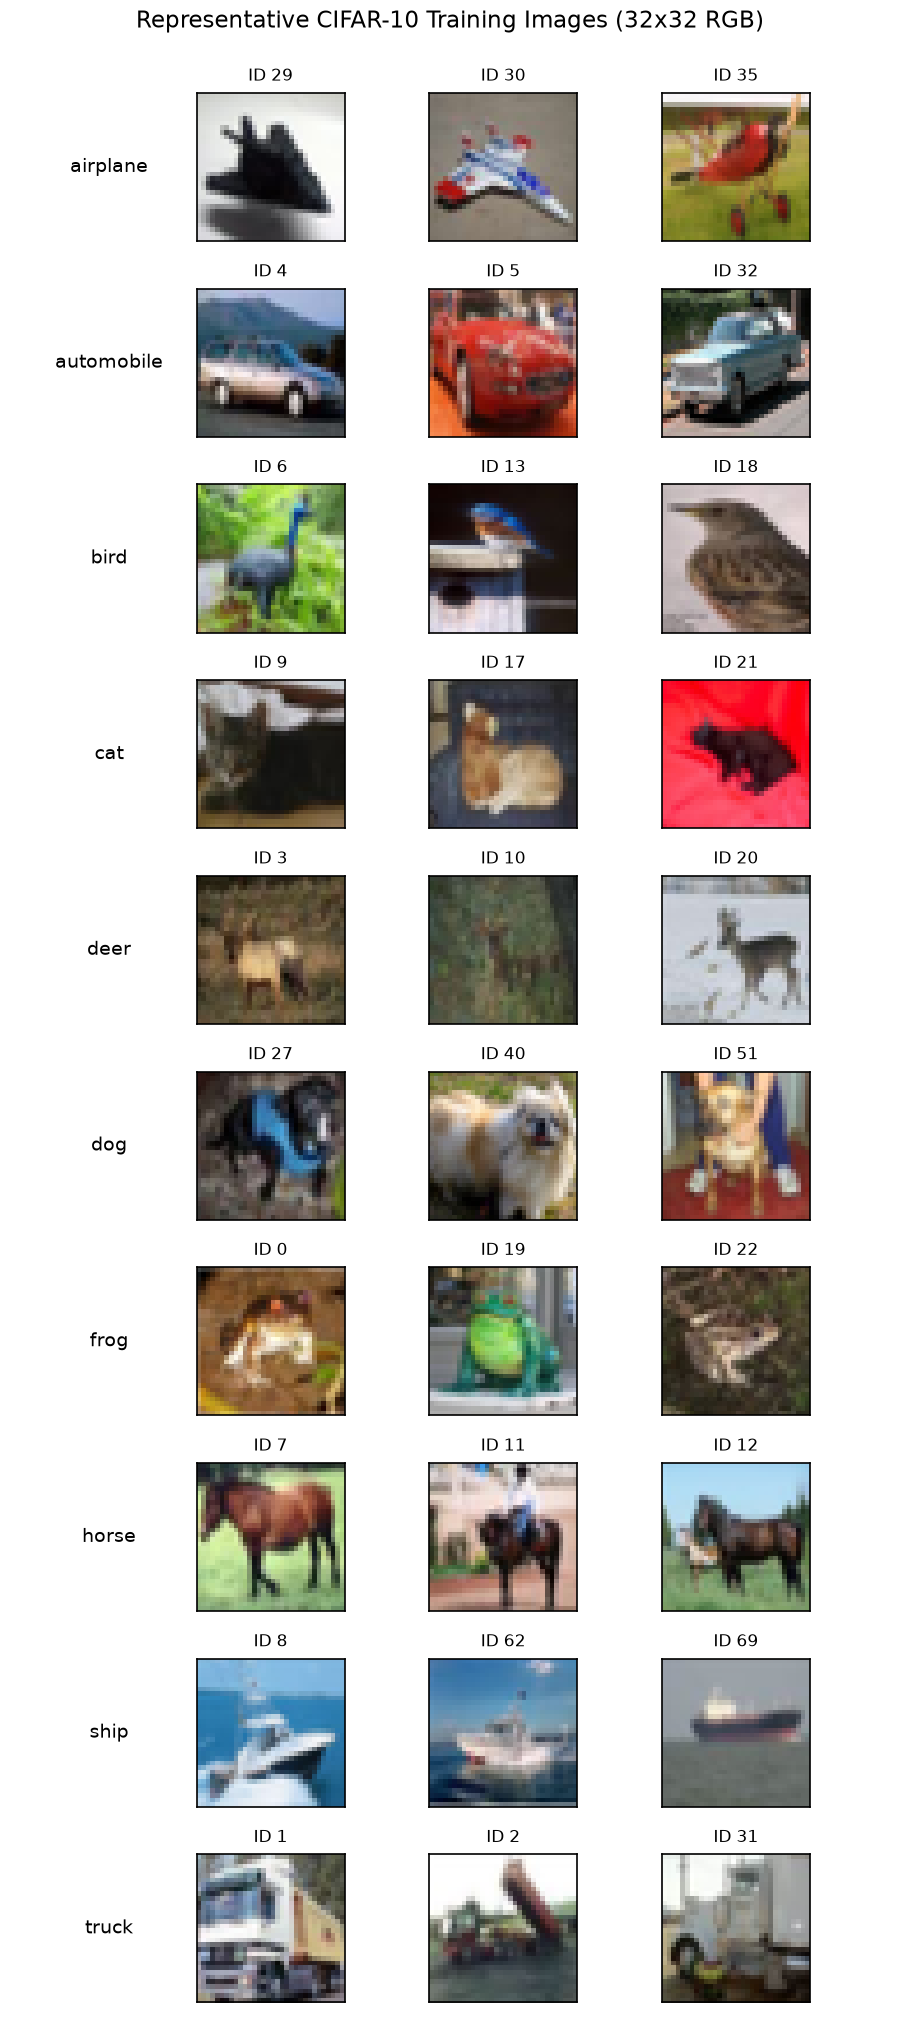

In [3]:
# 3. Task 1 结果展示：数据分布、统计量与样例图
t1 = load_json(results_dir / "task1_data_summary.json")
print("Image shape (H,W,C):", t1["image_shape_hwc"], "| dtype:", t1["dtype"],
      "| pixel range:", (t1["pixel_min"], t1["pixel_max"]))
print("Split counts:", t1["counts"])
display(pd.DataFrame(t1["train_only_stats"], index=["red", "green", "blue"]))
display(pd.DataFrame(t1["class_distribution"]).T)
display(Image(filename=str(REPO_DIR / t1["figures"]["class_distribution"])))
display(Image(filename=str(REPO_DIR / t1["figures"]["sample_grid"])))

In [4]:
# 4. Task 2 架构核对：AlexNet vs ResNet-18 特征图形状与参数量
profiles = load_json(results_dir / "task2_architecture_profiles.json")
for name, prof in profiles.items():
    print(f"\n=== {name} | params={prof['parameters']['total_params']:,} ===")
    display(pd.DataFrame(prof["stage_shapes"]))


=== alexnet_cifar | params=6,976,842 ===


,stage,shape
0,stage1,"[1, 64, 16, 16]"
1,stage2,"[1, 192, 8, 8]"
2,stage3,"[1, 256, 4, 4]"
3,classifier,"[1, 10]"



=== resnet18_cifar | params=11,173,962 ===


,stage,shape
0,stem,"[1, 64, 32, 32]"
1,stage1,"[1, 64, 32, 32]"
2,stage2,"[1, 128, 16, 16]"
3,stage3,"[1, 256, 8, 8]"
4,stage4,"[1, 512, 4, 4]"
5,head,"[1, 10]"


,exp_id,task,owner,model,seed,epochs,batch_size,optimizer,lr,weight_decay,...,total_train_time_sec,peak_gpu_mem_mb,best_epoch,best_val_acc,best_val_ce,final_train_eval_acc,clean_test_acc,macro_f1,bs1_latency_ms,bs128_throughput_imgs_per_sec
0,t2_alexnet_cifar_baseline_s42,task2,role_a,alexnet_cifar,42,30,128,sgd,0.01,0.0005,...,248.240,316.07,24,0.830,0.902950,1.0,0.8214,0.820482,3.059050,41853.673019
1,t2_resnet18_cifar_baseline_s42,task2,role_a,resnet18_cifar,42,30,128,sgd,0.10,0.0005,...,684.971,834.62,28,0.873,0.422264,1.0,0.8701,0.869797,11.627854,11404.723338


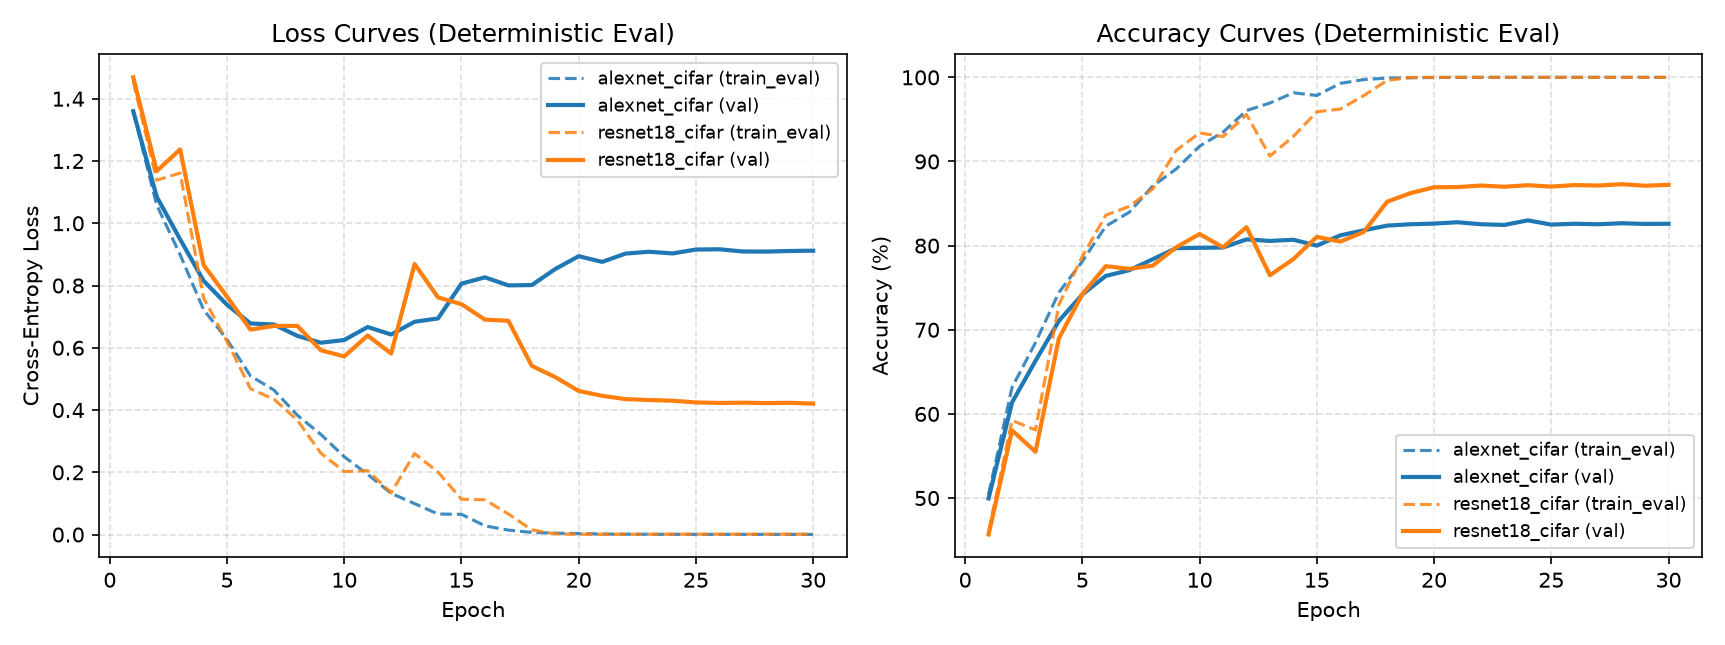

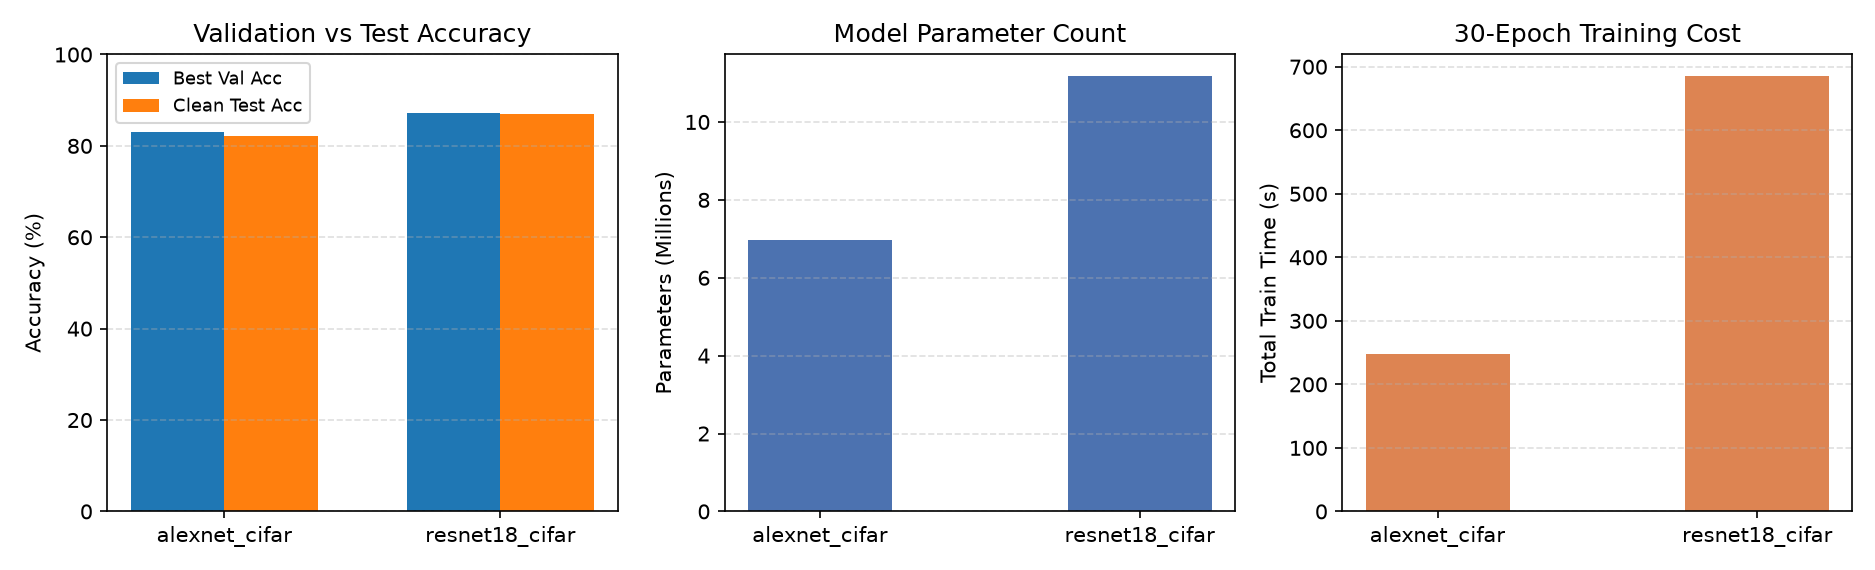


Registered checkpoints in manifest:


,exp_id,model,owner,git_commit,drive_rel_path,best_epoch,best_val_acc,clean_test_acc,notes
0,t6_alexnet_cifar_no_aug_s42,alexnet_cifar,role_c,unknown,checkpoints/t6_alexnet_cifar_no_aug_s42/best.pt,28,0.8296,None,Role C task6 frozen T4 matrix row (alexnet_cif...
1,t4_resnet18_cifar_no_aug_s42,resnet18_cifar,role_c,unknown,checkpoints/t4_resnet18_cifar_no_aug_s42/best.pt,28,0.8742,None,Role C task4 frozen T4 matrix row (resnet18_ci...
2,t4_resnet18_cifar_crop_flip_s42,resnet18_cifar,role_c,unknown,checkpoints/t4_resnet18_cifar_crop_flip_s42/be...,30,0.9304,None,Role C task4 frozen T4 matrix row (resnet18_ci...
3,t6_resnet18_cifar_crop_flip_s0,resnet18_cifar,role_c,unknown,checkpoints/t6_resnet18_cifar_crop_flip_s0/bes...,30,0.9302,None,Role C task6 frozen T4 matrix row (resnet18_ci...
4,t6_resnet18_cifar_crop_flip_s123,resnet18_cifar,role_c,unknown,checkpoints/t6_resnet18_cifar_crop_flip_s123/b...,29,0.9336,None,Role C task6 frozen T4 matrix row (resnet18_ci...


In [5]:
# 5. Task 2 数值对比、学习曲线与检查点交接清单
summary_df = pd.read_csv(results_dir / "summary.csv")
display(summary_df)
display(Image(filename=str(results_dir / "figures" / "t2_learning_curves.png")))
display(Image(filename=str(results_dir / "figures" / "t2_baseline_comparison.png")))

manifest = load_json(results_dir / "checkpoints_manifest.json")
print("\nRegistered checkpoints in manifest:")
display(pd.DataFrame(manifest["checkpoints"]))